In [1]:
%pip -q install opencv-python-headless numpy matplotlib ultralytics

In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

print("OpenCV Version:", cv2.__version__)
print("NumPy Version:", np.__version__)
print("OpenCV and NumPy loaded successfully")

OpenCV Version: 5.0.0
NumPy Version: 2.4.6
OpenCV and NumPy loaded successfully


In [3]:
# Create a small example array so we can inspect image dimensions
sample_array = np.zeros((720, 1280, 3), dtype=np.uint8)
print("Image shape:", sample_array.shape)
print("Data type:", sample_array.dtype)

Image shape: (720, 1280, 3)
Data type: uint8


Saving f8a95fe9238e83a493ecfc4c872dbdae.jpg to f8a95fe9238e83a493ecfc4c872dbdae.jpg
Loaded: f8a95fe9238e83a493ecfc4c872dbdae.jpg
Shape: (640, 640, 3)


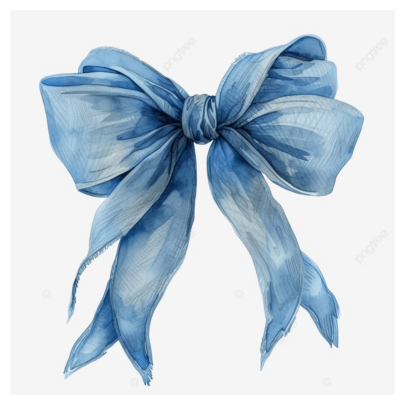

In [5]:
from google.colab import files
from IPython.display import display
from PIL import Image
import io

uploaded = files.upload()  # Choose a JPG or PNG image
image_name = next(iter(uploaded))
img = cv2.imdecode(np.frombuffer(uploaded[image_name], np.uint8), cv2.IMREAD_COLOR)

print("Loaded:", image_name)
print("Shape:", img.shape)
plt.figure(figsize=(8, 5))
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.axis("off");

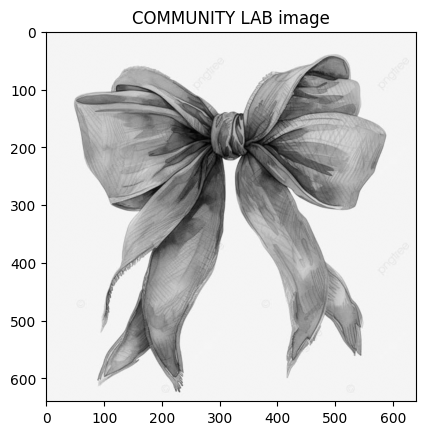

In [6]:
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
plt.imshow(gray, cmap="gray")
plt.title("COMMUNITY LAB image")
plt.axis("on");

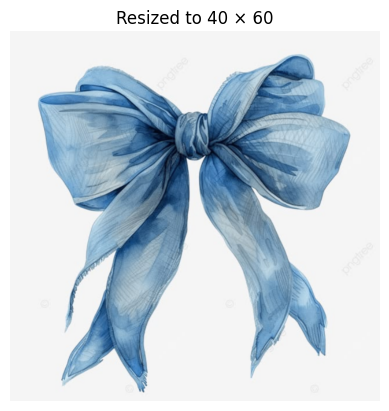

In [7]:
resized = cv2.resize(img, (740,740))  # (width, height)
plt.imshow(cv2.cvtColor(resized, cv2.COLOR_BGR2RGB))
plt.title("Resized to 40 × 60")
plt.axis("off");

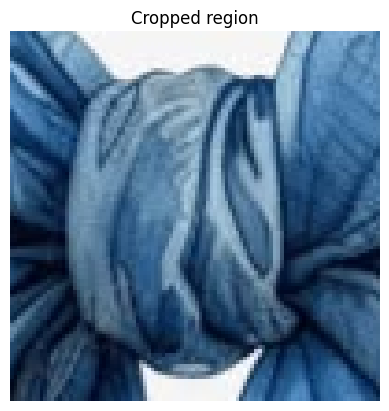

In [9]:
crop = img[130:230,270:370]  # img[y1:y2, x1:x2]
plt.imshow(cv2.cvtColor(crop, cv2.COLOR_BGR2RGB))
plt.title("Cropped region")
plt.axis("off");

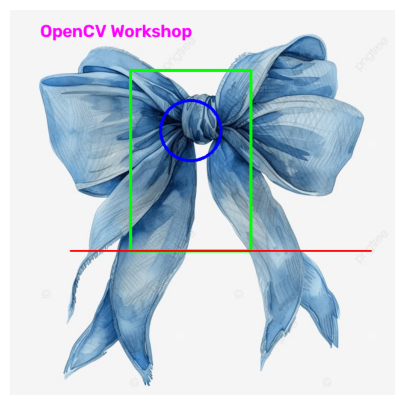

In [12]:
drawing = img.copy()

# Rectangle
cv2.rectangle(drawing, (200, 100), (400, 400), (0, 255, 0), 3)

# Circle
cv2.circle(drawing, (300, 200), 50, (255, 0, 0), 3)

# Line
cv2.line(drawing, (100, 400), (600, 400), (0, 0, 255), 2)

# Text
cv2.putText(drawing, "OpenCV Workshop", (50, 45),
            cv2.FONT_HERSHEY_SIMPLEX, 1, (255, 0, 255), 2)
plt.figure(figsize=(8, 5))
plt.imshow(cv2.cvtColor(drawing, cv2.COLOR_BGR2RGB))
plt.axis("off");

Live-video helper ready. Each detection demo below starts its own continuous browser-camera stream.
Upload one sample image for the basic image-processing exercises.


Saving images (28).jpeg to images (28).jpeg
Sample image loaded for image-processing concepts. Detection demos use live video.


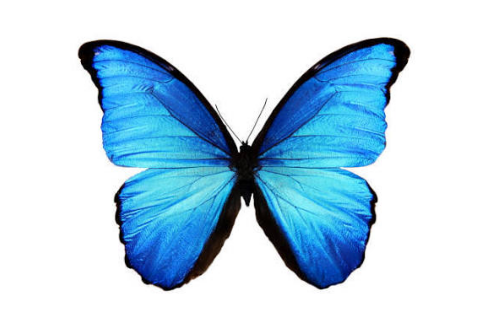

In [13]:
from IPython.display import Javascript, display
from google.colab.output import eval_js
from base64 import b64decode

def take_browser_photo(filename="browser_photo.jpg", quality=0.9):
    js = Javascript(r'''
    async function takePhoto(quality) {
      const div = document.createElement('div');
      const title = document.createElement('p');
      title.textContent = 'Allow camera access, position yourself, then click Capture.';
      div.appendChild(title);
      const video = document.createElement('video');
      video.style.display = 'block';
      video.style.maxWidth = '100%';
      const stream = await navigator.mediaDevices.getUserMedia({video: true});
      video.srcObject = stream;
      await video.play();
      await new Promise(resolve => {
        const button = document.createElement('button');
        button.textContent = 'Capture photo';
        div.appendChild(button);
        button.onclick = resolve;
        document.body.appendChild(div);
      });
      const canvas = document.createElement('canvas');
      canvas.width = video.videoWidth;
      canvas.height = video.videoHeight;
      canvas.getContext('2d').drawImage(video, 0, 0);
      stream.getTracks().forEach(track => track.stop());
      div.remove();
      return canvas.toDataURL('image/jpeg', quality);
    }
    ''')
    display(js)
    data = eval_js(f'takePhoto({quality})')
    binary = b64decode(data.split(',')[1])
    with open(filename, 'wb') as f:
        f.write(binary)
    return filename



# Reusable live browser-camera loop for every detection project in this notebook.
# The browser sends one current frame at a time to the Colab Python runtime.
import time
from IPython.display import HTML, display

def run_live_video(process_frame, title="Live OpenCV Detection", delay=0.08, max_width=720):
    """Run process_frame(frame_bgr) continuously on live browser-camera frames.
    Stop by clicking Runtime → Interrupt execution (or the ■ stop button).
    """
    setup_js = r"""
    (async () => {
      if (window._mosiCvStream) {
        window._mosiCvStream.getTracks().forEach(t => t.stop());
      }
      const stream = await navigator.mediaDevices.getUserMedia({
        video: { facingMode: 'user', width: {ideal: 640}, height: {ideal: 480} }, audio: false
      });
      const video = document.createElement('video');
      video.autoplay = true; video.muted = true; video.playsInline = true;
      video.srcObject = stream;
      await video.play();
      const canvas = document.createElement('canvas');
      const ctx = canvas.getContext('2d');
      window._mosiCvStream = stream;
      window._mosiCvVideo = video;
      window._mosiCvCanvas = canvas;
      window._mosiCvGetFrame = () => {
        canvas.width = video.videoWidth; canvas.height = video.videoHeight;
        ctx.drawImage(video, 0, 0, canvas.width, canvas.height);
        return canvas.toDataURL('image/jpeg', 0.72);
      };
      window._mosiCvStop = () => {
        if (window._mosiCvStream) window._mosiCvStream.getTracks().forEach(t => t.stop());
        window._mosiCvStream = null;
        return true;
      };
      return true;
    })()
    """
    eval_js(setup_js)
    output = display(HTML(f'<b>{title}</b><p>Starting live video… interrupt the cell to stop.</p>'), display_id=True)
    try:
        while True:
            data_url = eval_js('window._mosiCvGetFrame()')
            frame_bytes = b64decode(data_url.split(',', 1)[1])
            frame = cv2.imdecode(np.frombuffer(frame_bytes, np.uint8), cv2.IMREAD_COLOR)
            if frame is None:
                continue
            processed = process_frame(frame)
            if processed is None:
                processed = frame
            h, w = processed.shape[:2]
            if w > max_width:
                processed = cv2.resize(processed, (max_width, int(h * max_width / w)))
            rgb = cv2.cvtColor(processed, cv2.COLOR_BGR2RGB)
            ok, encoded = cv2.imencode('.jpg', cv2.cvtColor(rgb, cv2.COLOR_RGB2BGR), [int(cv2.IMWRITE_JPEG_QUALITY), 75])
            if ok:
                import base64
                b64 = base64.b64encode(encoded).decode('ascii')
                output.update(HTML(f'<div><b>{title}</b><br><img style="max-width:100%;height:auto" src="data:image/jpeg;base64,{b64}"><p>Live feed running — use Interrupt execution (■) to stop.</p></div>'))
            time.sleep(delay)
    except KeyboardInterrupt:
        print('Live video stopped.')
    finally:
        try:
            eval_js('window._mosiCvStop && window._mosiCvStop()')
        except Exception:
            pass

print("Live-video helper ready. Each detection demo below starts its own continuous browser-camera stream.")

# Still-image upload is only for the basic image-processing lesson (resize, crop, blur, etc.).
# All detection demos below use live video instead of this uploaded still image.
from google.colab import files
print("Upload one sample image for the basic image-processing exercises.")
image_upload = files.upload()
image_name = next(iter(image_upload))
camera_img = cv2.imdecode(np.frombuffer(image_upload[image_name], np.uint8), cv2.IMREAD_COLOR)
if camera_img is None:
    raise ValueError("Could not read that image. Upload a JPG or PNG file.")
print("Sample image loaded for image-processing concepts. Detection demos use live video.")
plt.figure(figsize=(7, 4))
plt.imshow(cv2.cvtColor(camera_img, cv2.COLOR_BGR2RGB))
plt.axis("off");


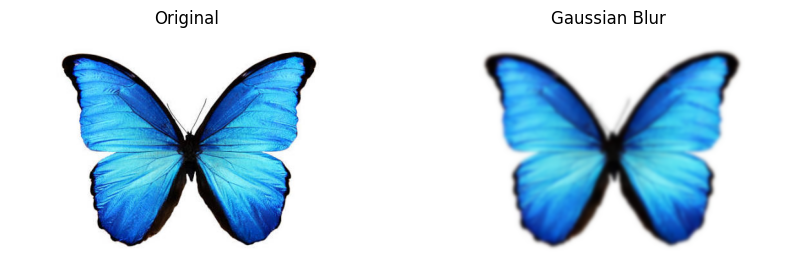

In [14]:
blur = cv2.GaussianBlur(camera_img, (15, 15), 0)

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(camera_img, cv2.COLOR_BGR2RGB))
plt.title("Original")
plt.axis("off")
plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(blur, cv2.COLOR_BGR2RGB))
plt.title("Gaussian Blur")
plt.axis("off");


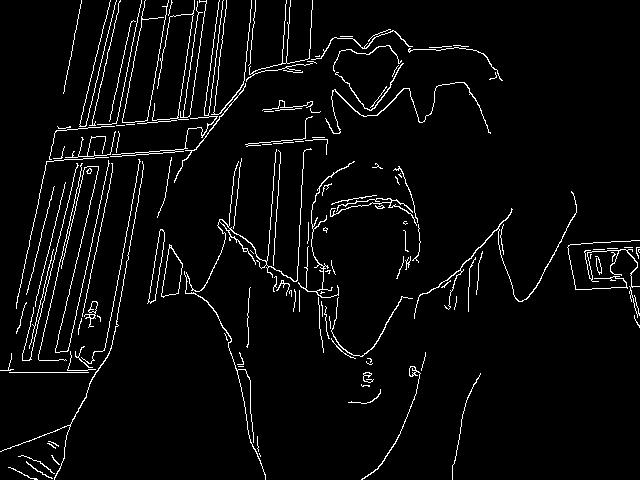

Live video stopped.


In [16]:
def edge_processor(frame):
    edges = cv2.Canny(cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY), 100, 200)
    return cv2.cvtColor(edges, cv2.COLOR_GRAY2BGR)

run_live_video(edge_processor, "Live Canny Edge Detection")


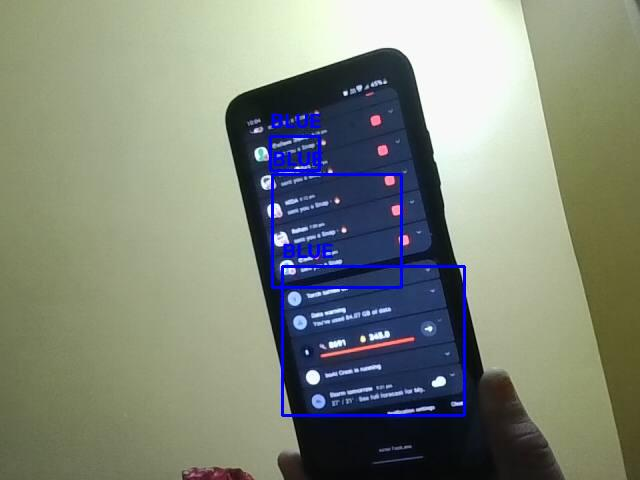

Live video stopped.


In [18]:
def blue_tracker(frame):
    hsv = cv2.cvtColor(frame, cv2.COLOR_BGR2HSV)
    # Typical range for blue in HSV
    lower_blue = np.array([100, 150, 50])
    upper_blue = np.array([140, 255, 255])
    mask = cv2.inRange(hsv, lower_blue, upper_blue)
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    output = frame.copy()
    for cnt in contours:
        if cv2.contourArea(cnt) > 500:
            x, y, w, h = cv2.boundingRect(cnt)
            # BGR for blue is (255, 0, 0)
            cv2.rectangle(output, (x, y), (x+w, y+h), (255, 0, 0), 2)
            cv2.putText(output, "BLUE", (x, max(25, y-8)), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (255, 0, 0), 2)
    return output

run_live_video(blue_tracker, "Live Blue Color Tracking")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings



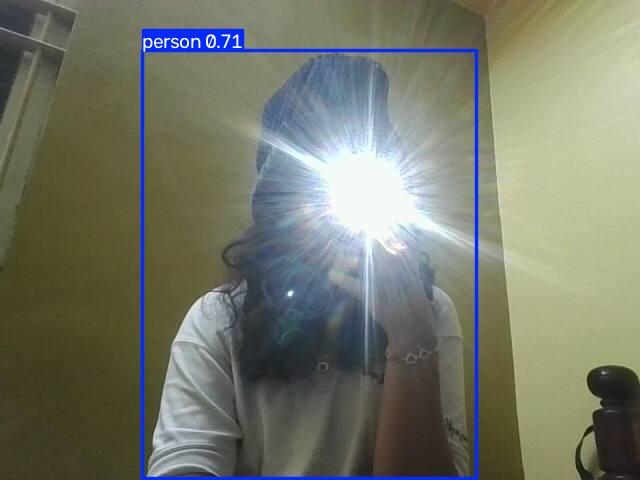

Live video stopped.


In [19]:
from ultralytics import YOLO

model = YOLO("yolov8n.pt")  # small, fast model

def yolo_processor(frame):
    result = model(frame, verbose=False)[0]
    return result.plot()

run_live_video(yolo_processor, "Live YOLO Object Detection", delay=0.12)


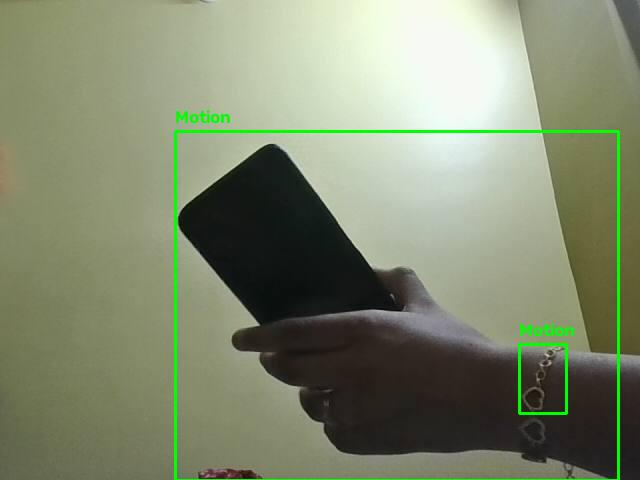

Live video stopped.


In [20]:
# Project 4: Live Motion Detection

def make_motion_processor():
    previous_gray = {"frame": None}
    def process(frame):
        gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
        gray = cv2.GaussianBlur(gray, (5, 5), 0)
        output = frame.copy()
        if previous_gray["frame"] is None:
            previous_gray["frame"] = gray
            cv2.putText(output, "Move in front of camera", (15, 30), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0,255,0), 2)
            return output
        diff = cv2.absdiff(previous_gray["frame"], gray)
        _, mask = cv2.threshold(diff, 20, 255, cv2.THRESH_BINARY)
        mask = cv2.dilate(mask, None, iterations=2)
        contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        for cnt in contours:
            if cv2.contourArea(cnt) > 700:
                x, y, w, h = cv2.boundingRect(cnt)
                cv2.rectangle(output, (x, y), (x+w, y+h), (0,255,0), 2)
                cv2.putText(output, "Motion", (x, max(25, y-8)), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0,255,0), 2)
        previous_gray["frame"] = gray
        return output
    return process

run_live_video(make_motion_processor(), "Project 4 — Live Motion Detection")

Upload ONE image of the empty background (no person or red cloth).


Saving red screen'.png to red screen' (1).png



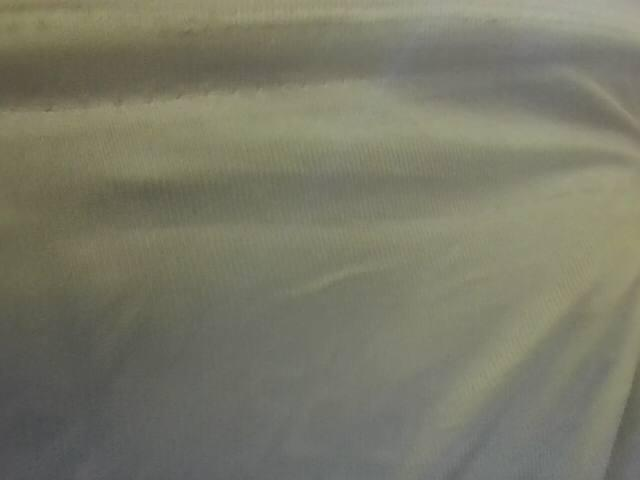

Live video stopped.


In [25]:
# Project 6: Live Invisible Cloak
from google.colab import files

print("Upload ONE image of the empty background (no person or red cloth).")
bg_upload = files.upload()
bg_name = next(iter(bg_upload))
background_original = cv2.imdecode(np.frombuffer(bg_upload[bg_name], np.uint8), cv2.IMREAD_COLOR)

def cloak_processor(frame):
    background = cv2.resize(background_original, (frame.shape[1], frame.shape[0]))
    hsv = cv2.cvtColor(frame, cv2.COLOR_BGR2HSV)
    lower_red1, upper_red1 = np.array([0, 120, 70]), np.array([10, 255, 255])
    lower_red2, upper_red2 = np.array([170, 120, 70]), np.array([180, 255, 255])
    mask = cv2.bitwise_or(cv2.inRange(hsv, lower_red1, upper_red1), cv2.inRange(hsv, lower_red2, upper_red2))
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, np.ones((3,3), np.uint8))
    mask_inv = cv2.bitwise_not(mask)
    bg_part = cv2.bitwise_and(background, background, mask=mask)
    fg_part = cv2.bitwise_and(frame, frame, mask=mask_inv)
    return cv2.add(bg_part, fg_part)

run_live_video(cloak_processor, "Project 6 — Live Invisible Cloak")


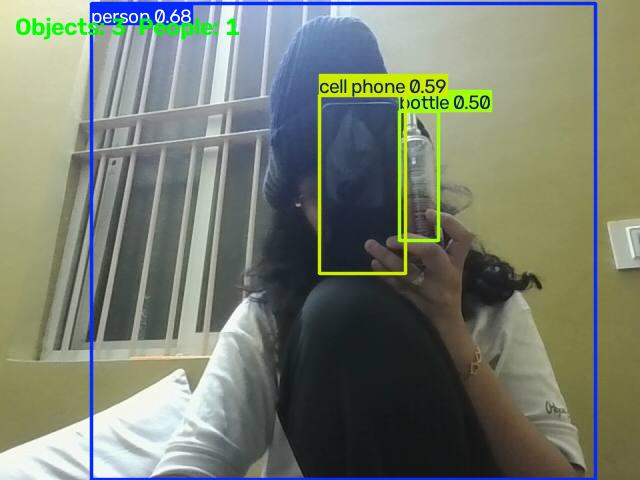

Live video stopped.


In [22]:
# Project 8: Live YOLO Object Counter

def yolo_counter_processor(frame):
    result = model(frame, verbose=False)[0]
    annotated = result.plot()
    count = len(result.boxes)
    people = sum(1 for box in result.boxes if int(box.cls[0]) == 0)
    cv2.putText(annotated, f"Objects: {count}  People: {people}", (15, 35),
                cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 255, 0), 2)
    return annotated

run_live_video(yolo_counter_processor, "Project 8 — Live YOLO Object Counter", delay=0.12)


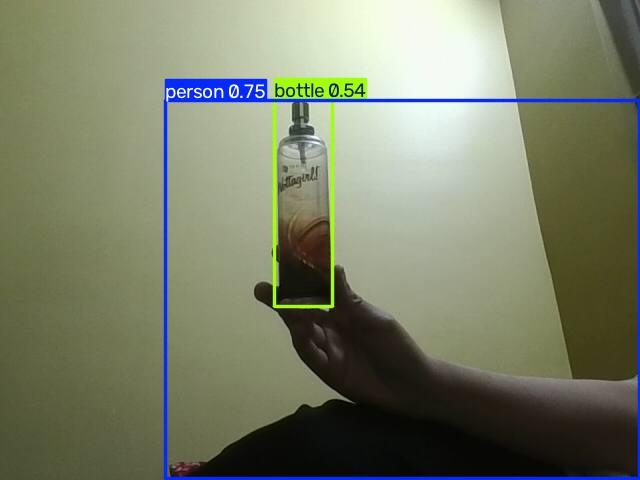

Live video stopped.


In [24]:
from ultralytics import YOLO

model = YOLO("yolov8n.pt")  # small, fast model

def yolo_processor(frame):
    result = model(frame, verbose=False)[0]
    return result.plot()

run_live_video(yolo_processor, "Live YOLO Object Detection", delay=0.12)